<a href="https://colab.research.google.com/github/Anshhh0306/machine-learning-tasks/blob/main/Crop_Recommendation_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Crop Recommendation Machine Learning Pipeline
### End-to-End Analysis: Data Preprocessing, Regression, Model Selection & Dimensionality Reduction

This notebook analyzes agricultural and climatic parameters (Nitrogen, Phosphorus, Potassium, Temperature, Humidity, pH, Rainfall) to evaluate multiple machine learning algorithms for optimal crop recommendation.

## Step 0: Environment Setup & Data Loading

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load dataset
csv_path = 'Crop_recommendation.csv'
if not os.path.exists(csv_path):
    raise FileNotFoundError(f"{csv_path} not found. Please upload it or ensure it is in the working directory.")

df = pd.read_csv(csv_path)
print(f"Dataset loaded successfully: {df.shape[0]} samples, {df.shape[1]} columns.")

Dataset loaded successfully: 2200 samples, 8 columns.


## Task 1: Building Data Pre-processing Pipeline
- Verify missing values and duplicates
- Feature and target separation
- Target label encoding for 22 crop classes
- Stratified 80/20 train/test split
- Feature scaling using `StandardScaler`

In [ ]:
# Basic sanity checks
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

feature_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X = df[feature_cols]
y_raw = df['label']

# Encode categorical target labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y_raw)

# Stratified train-test split (80-20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Feature Scaling (fit only on training set to prevent leakage)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_cols)

print(f"Task 1 complete: {X_train_scaled.shape[0]} train rows, {X_test_scaled.shape[0]} test rows.")
X_train_scaled.head()

Missing values: 0
Duplicate rows: 0
Task 1 complete: 1760 train rows, 440 test rows.


,N,P,K,temperature,humidity,ph,rainfall
0,-1.371628,-1.072910,-0.673510,0.819481,0.924395,0.937545,0.199440
1,-1.127411,2.084513,3.015261,0.783251,0.426613,-1.153846,-0.643677
2,-1.073140,0.536162,-0.476250,-0.879968,-2.186291,-1.107452,0.694001
3,-0.340487,-0.465713,-0.594606,0.138043,-0.459237,-0.229482,-1.231744
4,-0.883193,-1.255069,-0.791866,-2.563232,0.915842,-0.341959,0.289941


## Task 2: Building Linear Regression Pipeline
We set up a regression pipeline predicting the continuous variable `rainfall` based on soil nutrients and local temperatures.

In [ ]:
# Target: Rainfall (Continuous Variable)
reg_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph']
X_reg = df[reg_cols]
y_reg = df['rainfall']

X_tr, X_te, y_tr, y_te = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

scaler_reg = StandardScaler()
X_tr_sc = scaler_reg.fit_transform(X_tr)
X_te_sc = scaler_reg.transform(X_te)

lr = LinearRegression()
lr.fit(X_tr_sc, y_tr)
y_pred = lr.predict(X_te_sc)

print("Linear Regression Performance:")
print(f" - R^2 Score: {r2_score(y_te, y_pred):.4f}")
print(f" - RMSE:      {np.sqrt(mean_squared_error(y_te, y_pred)):.4f}")
print(f" - MAE:       {mean_absolute_error(y_te, y_pred):.4f}")
print("\n[Note] Low R^2 (~0.01) is expected: rainfall is an external atmospheric parameter\n       rather than a causal consequence of soil chemical composition.")

Linear Regression Performance:
 - R^2 Score: 0.0124
 - RMSE:      54.5257
 - MAE:       41.2479

[Note] Low R^2 (~0.01) is expected: rainfall is an external atmospheric parameter
       rather than a causal consequence of soil chemical composition.


## Task 3: Building Cross-Validation Pipeline
We evaluate generalization capability using 5-Fold Cross Validation and tune Random Forest hyperparameters using `GridSearchCV` on the training partition.

In [ ]:
# 1. 5-Fold CV on Regression
kf = KFold(n_splits=5, shuffle=True, random_state=42)
r2_cv = cross_val_score(LinearRegression(), X_tr_sc, y_tr, cv=kf, scoring='r2')
print(f"5-Fold Regression Mean R^2: {r2_cv.mean():.4f} (+/- {r2_cv.std():.4f})")

# 2. Stratified 5-Fold CV on Logistic Regression (evaluated on train set)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf_res = cross_val_score(
    LogisticRegression(max_iter=1000, random_state=42),
    X_train_scaled, y_train,
    cv=skf, scoring='accuracy'
)
print(f"5-Fold Stratified CV Mean Accuracy: {clf_res.mean():.4f} (+/- {clf_res.std():.4f})")

# 3. GridSearchCV for Random Forest Classifier
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20, None],
    'criterion': ['gini', 'entropy']
}
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=skf, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print(f"Best Hyperparameters: {grid.best_params_}")
print(f"Best CV Score:        {grid.best_score_:.4f}")

5-Fold Regression Mean R^2: 0.0227 (+/- 0.0284)
5-Fold Stratified CV Mean Accuracy: 0.9682 (+/- 0.0066)
Best Hyperparameters: {'criterion': 'gini', 'max_depth': 10, 'n_estimators': 100}
Best CV Score:        0.9943


## Task 4: Performance Metrics & Evaluation
We test our best tuned Random Forest model on the unseen test set, generating precision, recall, f1-score, and a confusion matrix heatmap.

Random Forest Test Accuracy: 0.9955

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.

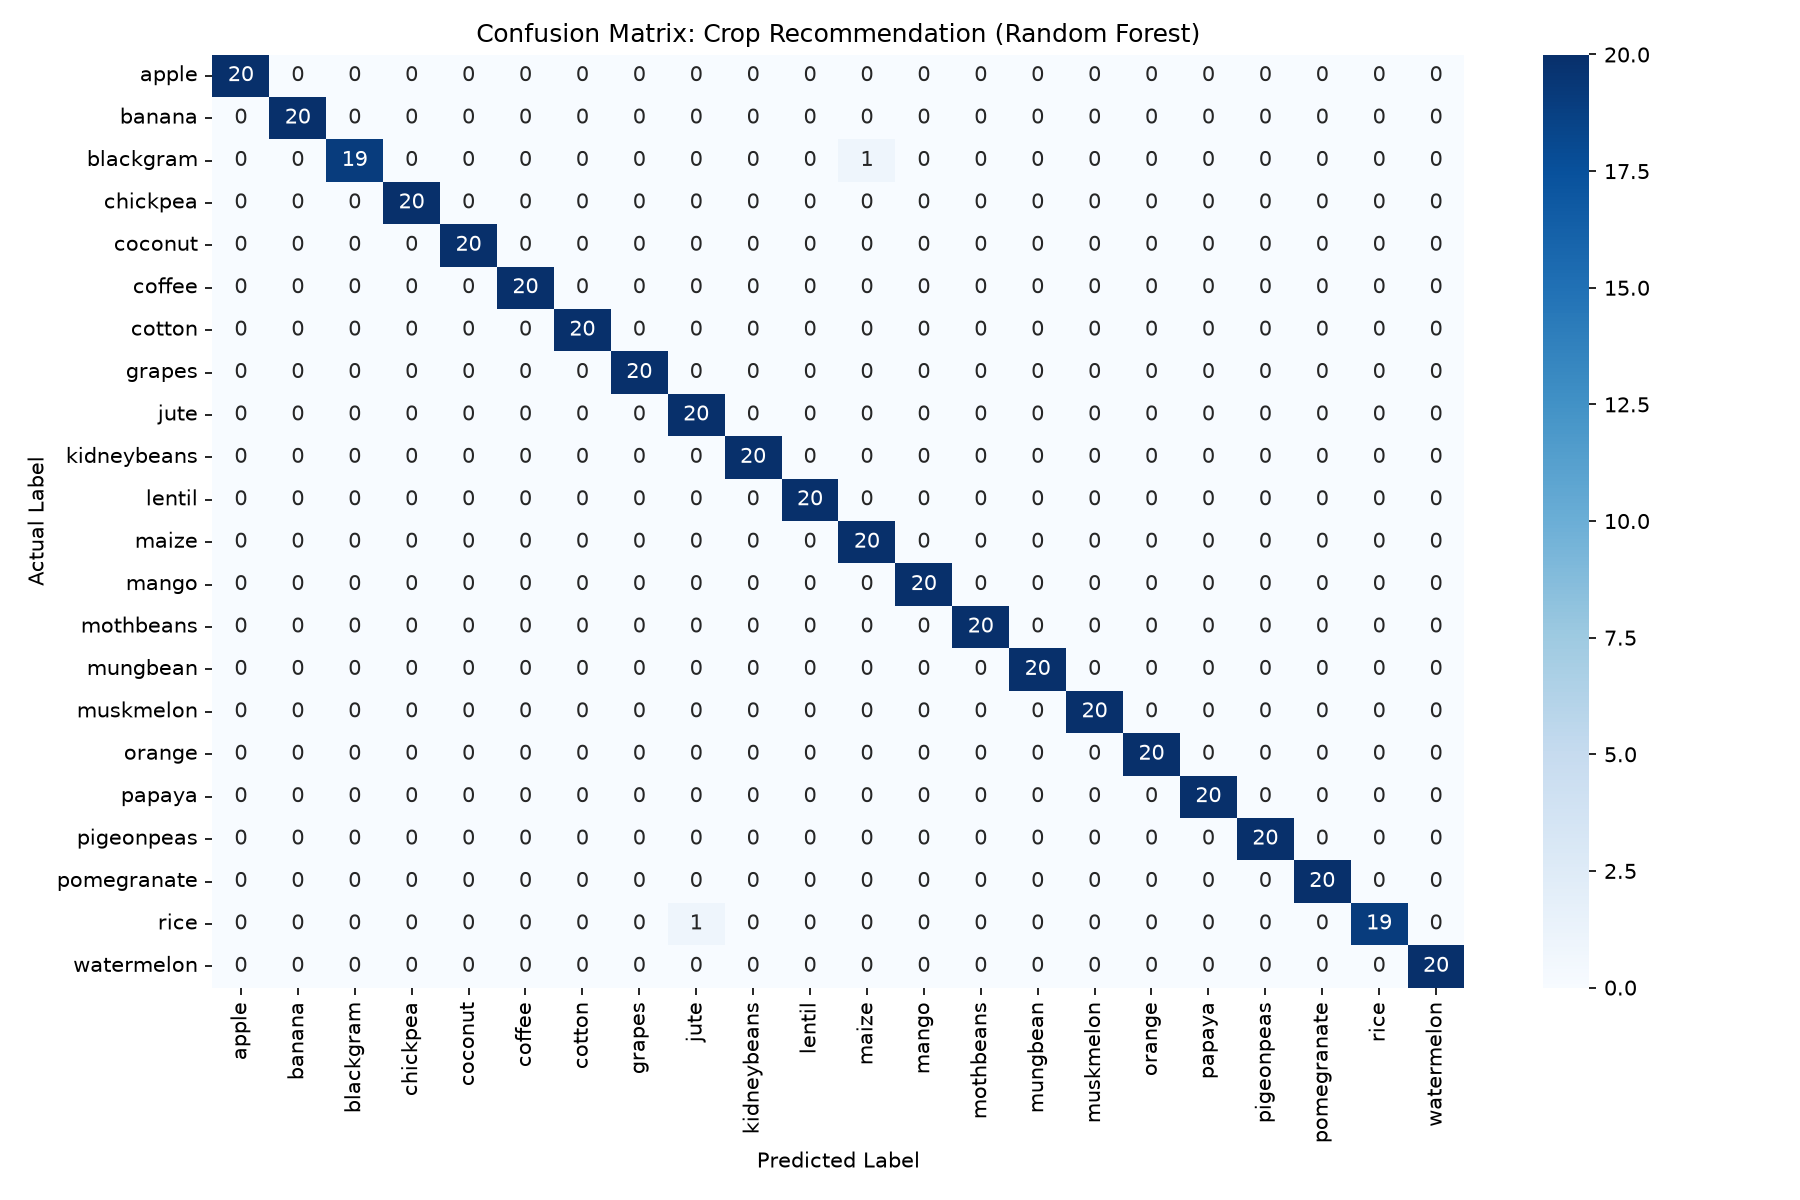

In [ ]:
best_clf = grid.best_estimator_
y_pred_clf = best_clf.predict(X_test_scaled)

print(f"Random Forest Test Accuracy: {accuracy_score(y_test, y_pred_clf):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_clf, target_names=encoder.classes_))

# Confusion Matrix Heatmap
plt.figure(figsize=(12, 8))
cm = confusion_matrix(y_test, y_pred_clf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=encoder.classes_, yticklabels=encoder.classes_)
plt.title('Confusion Matrix: Crop Recommendation (Random Forest)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## Task 5: Multiple Linear Regression Coefficients Analysis
Here we inspect the model intercept and the learned weights for each input feature to interpret their relative impact.

In [ ]:
print(f"Model Intercept: {lr.intercept_:.4f}\n")
coeff_df = pd.DataFrame({
    'Feature': reg_cols,
    'Coefficient': lr.coef_
}).sort_values(by='Coefficient', ascending=False).reset_index(drop=True)

coeff_df

Model Intercept: 102.6613



,Feature,Coefficient
0,humidity,5.864026
1,N,2.733493
2,P,0.916854
3,temperature,-3.966281
4,K,-6.754377
5,ph,-8.417931


## Task 6: Logistic Regression for Crop Classification
We train a multinomial Logistic Regression classifier to serve as a linear baseline for crop classification.

In [ ]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

train_acc = log_reg.score(X_train_scaled, y_train)
test_acc = log_reg.score(X_test_scaled, y_test)

print(f"Logistic Regression Training Accuracy: {train_acc:.4f}")
print(f"Logistic Regression Testing Accuracy:  {test_acc:.4f}")

Logistic Regression Training Accuracy: 0.9739
Logistic Regression Testing Accuracy:  0.9727


## Task 7: Principal Component Analysis (PCA)
We examine how much variance is captured across orthogonal principal components and determine how many components are needed to retain 95% of total variance.

In [ ]:
pca = PCA(n_components=None)
X_train_pca = pca.fit_transform(X_train_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

for i, (var, cum_var) in enumerate(zip(explained_variance, cumulative_variance), 1):
    print(f"PC{i:02d}: Explained = {var:.4f} ({var*100:5.2f}%) | Cumulative = {cum_var:.4f} ({cum_var*100:5.2f}%)")

# Component retention for 95% variance
pca_95 = PCA(n_components=0.95, random_state=42)
X_train_pca_95 = pca_95.fit_transform(X_train_scaled)
X_test_pca_95 = pca_95.transform(X_test_scaled)

print(f"\nNumber of components selected to retain >= 95% variance: {pca_95.n_components_} of {len(feature_cols)}")

Principal Components Variance Breakdown:
 - PC01: Explained = 0.2738 (27.38%) | Cumulative = 0.2738 (27.38%)
 - PC02: Explained = 0.1867 (18.67%) | Cumulative = 0.4605 (46.05%)
 - PC03: Explained = 0.1531 (15.31%) | Cumulative = 0.6136 (61.36%)
 - PC04: Explained = 0.1461 (14.61%) | Cumulative = 0.7597 (75.97%)
 - PC05: Explained = 0.1144 (11.44%) | Cumulative = 0.8740 (87.40%)
 - PC06: Explained = 0.0984 ( 9.84%) | Cumulative = 0.9724 (97.24%)
 - PC07: Explained = 0.0276 ( 2.76%) | Cumulative = 1.0000 (100.00%)

Number of components selected to retain >= 95% variance: 6 of 7


## Task 8: Gaussian Naive Bayes Classification
We implement a Gaussian Naive Bayes classifier on the standardized environmental features.

In [ ]:
nb_classifier = GaussianNB()
nb_classifier.fit(X_train_scaled, y_train)

y_pred_nb = nb_classifier.predict(X_test_scaled)
nb_accuracy = accuracy_score(y_test, y_pred_nb)

print(f"Gaussian Naive Bayes Testing Accuracy: {nb_accuracy:.4f} ({nb_accuracy*100:.2f}%)")

Gaussian Naive Bayes Testing Accuracy: 0.9955 (99.55%)


## Task 9: Support Vector Machine (SVM)
We train an SVM classifier with an RBF (Radial Basis Function) kernel on the scaled features.

In [ ]:
svm_classifier = SVC(kernel='rbf', C=1.0, random_state=42)
svm_classifier.fit(X_train_scaled, y_train)

y_pred_svm = svm_classifier.predict(X_test_scaled)
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print(f"Support Vector Machine (RBF Kernel) Testing Accuracy: {svm_accuracy:.4f} ({svm_accuracy*100:.2f}%)")

Support Vector Machine (RBF Kernel) Testing Accuracy: 0.9841 (98.41%)


## Summary: Comparative Model Benchmarking
Consolidated accuracy comparison across all evaluated classification models.

In [ ]:
results_summary = pd.DataFrame({
    'Model': [
        'Random Forest (Tuned)',
        'Gaussian Naive Bayes',
        'Support Vector Machine (RBF)',
        'Logistic Regression'
    ],
    'Test Accuracy': [
        accuracy_score(y_test, y_pred_clf),
        nb_accuracy,
        svm_accuracy,
        test_acc
    ]
}).sort_values(by='Test Accuracy', ascending=False).reset_index(drop=True)

results_summary

,Model,Test Accuracy
0,Random Forest (Tuned),0.995455
1,Gaussian Naive Bayes,0.995455
2,Support Vector Machine (RBF),0.984091
3,Logistic Regression,0.972727
